# Queima de Fusível de Capacitores Unipraias

## Filtro do Motor CC

In [93]:
import numpy as np
from IPython.display import display, Math, Latex

In [94]:
w1 = 2*np.pi*60
L5 = 181e-6
C5 = 1550e-6
w5 = 1/np.sqrt(L5*C5)
h5 = w5/w1
display(Math(r'h_5 ='+str(np.round(h5,2))))

<IPython.core.display.Math object>

In [95]:
L11 = 75e-6
C11 = 775e-6
w11 = 1/np.sqrt(L11*C11)
h11 = w11/w1
display(Math(r'h_{11} ='+str(np.round(h11,2))))

<IPython.core.display.Math object>

In [96]:
L17 = 88e-6
C17 = 275e-6
w17 = 1/np.sqrt(L17*C17)
h17 = w17/w1
display(Math(r'h_{17} ='+str(np.round(h17,2))))

<IPython.core.display.Math object>

In [97]:
def impedancia_filtro(ww, LL, CC):
    return 0.020 + 1j*ww*LL - 1j/(ww*CC)

In [98]:
f = np.linspace(60, 60*25, 2500)
w = 2*np.pi*f

In [99]:
Z5 = impedancia_filtro(w, L5, C5)
Z11 = impedancia_filtro(w, L11, C11)
Z17 = impedancia_filtro(w, L17, C17)
Y_paralelo = 1/Z5 + 1/Z11 + 1/Z17
Z_paralelo = 1 / Y_paralelo

In [100]:
p5 = 1.05
p11 = 1.025
p17 = 1.025
Z5p = impedancia_filtro(w, p5*L5, C5)
Z11p = impedancia_filtro(w, p11*L11, C11)
Z17p = impedancia_filtro(w, p17*L17, C17)
Y_paralelop = 1/Z5p + 1/Z11p + 1/Z17p
Z_paralelop = 1 / Y_paralelop

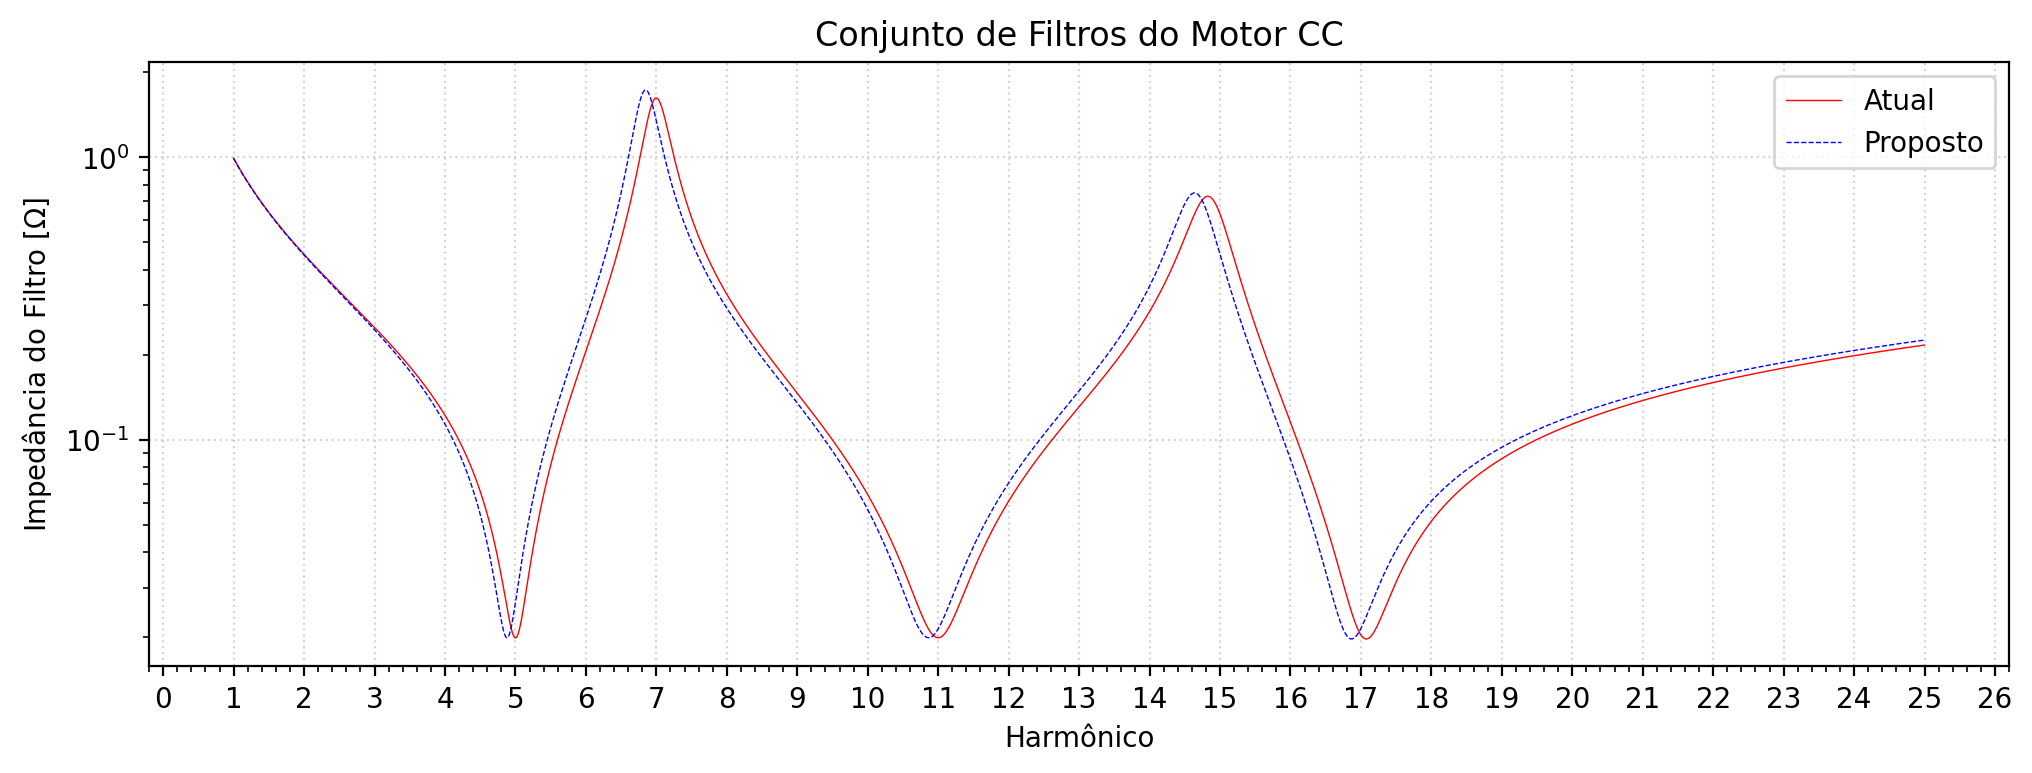

In [101]:
import matplotlib.pyplot as plt
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
fig, ax = plt.subplots(figsize=(12,4), dpi=200)
ax.plot(w/w1, np.abs(Z_paralelo), label='Atual', lw=0.5, color='red')
ax.plot(w/w1, np.abs(Z_paralelop), label='Proposto', lw=0.5, color='blue', ls="--")
# ax.plot(w/w1, Z5, label='5h', lw=0.5, color='red', ls='--')
# ax.plot(w/w1, Z11, label='11h', lw=0.5, color='green', ls='--')
# ax.plot(w/w1, Z17, label='17h', lw=0.5, color='blue', ls='--')
ax.set_title("Conjunto de Filtros do Motor CC")
ax.set_yscale('log')
ax.set_xlabel('Harmônico')
ax.set_ylabel('Impedância do Filtro $[\\Omega]$')
plt.legend()
plt.grid(alpha=0.5, ls=":")
ax.xaxis.set_major_locator(MultipleLocator(1))
# ax.xaxis.set_major_formatter('{x:.0f}')
ax.xaxis.set_minor_locator(MultipleLocator(0.2))
fig.show()

